# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

Taakverdeling

- Token indicators: IDS
- Bag-of-words: JULIUS
- extra of your choice: IDS


- log-linear: JULIUS
- single-hidden-layer MLP: IDS
- extra: JULIUS

In [1]:
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [2]:
from datasets import load_dataset
from collections import Counter
import numpy as np
import pandas as pd
from tokenizers import Tokenizer

In [3]:
# load and inspect dataset
ds = load_dataset("gsri-18/ISEAR-dataset-complete")

print(ds)
train = ds["train"]

emotions = train.unique("emotion")

print("Unique emotions:", emotions)
print("Number of emotions:", len(emotions))

# Count samples per emotion
print("\nEmotion distribution:")
print(Counter(train["emotion"]))

DatasetDict({
    train: Dataset({
        features: ['emotion', 'content', 'Unnamed: 2'],
        num_rows: 7516
    })
})
Unique emotions: ['joy', 'fear', 'anger', 'sadness', 'disgust', 'shame', 'guilt']
Number of emotions: 7

Emotion distribution:
Counter({'joy': 1092, 'sadness': 1082, 'anger': 1079, 'fear': 1076, 'shame': 1071, 'disgust': 1066, 'guilt': 1050})


## Train/test split maken

In [4]:
from sklearn.model_selection import train_test_split

df = ds["train"].to_pandas()

X = df["content"].tolist()
y = df["emotion"].tolist()

# 70% training, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

print(df.shape)
print("Training:", len(X_train))
print("Test:", len(X_test))

(7516, 3)
Training: 5261
Test: 2255


## tokenizer (CountVector)

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# gets used in TF-IDF as well:
features_used = 2000

# max tokens in dataset, with df=2: 3757
# use less tokens for the project to run faster (recommended: 1000)
tokenizer = CountVectorizer(max_features=features_used, min_df=2)
tokenizer.fit(X_train)

# get vocabulary
vocab = tokenizer.vocabulary_
vocab_size = len(vocab)

# tokenize a single text and return tokens and IDs
def encode(text):
    tokens = tokenizer.build_analyzer()(text)
    ids = [vocab[token] for token in tokens if token in vocab]
    return tokens, ids

# **Text representation spaces (BoW, Indicator, TF-IDF)**

In [6]:
def bag_of_words(text, tokenizer, vocab_size):

    # Tokenize text using the new tokenizer
    tokens, token_ids = encode(text)

    # Create an empty vector
    vector = np.zeros(vocab_size)

    # Count occurrences of token IDs
    for ids in token_ids:
        vector[ids] += 1

    return vector

def token_indicator(text):

    tokens, token_ids = encode(text)

    vector = np.zeros(vocab_size)

    # Set each occurring token to 1
    for token_id in set(token_ids):
        vector[token_id] = 1

    return vector

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=features_used,
    min_df=2
)

# fit on training texts
X_train_tf_idf = tfidf_vectorizer.fit_transform(X_train)
X_test_tf_idf = tfidf_vectorizer.transform(X_test)

print(X_train_tf_idf.shape)
print(X_test_tf_idf.shape)

(5261, 2000)
(2255, 2000)


## *Representation spaces on whole dataset*

In [8]:
# usES BoW on whole dataset

X_train_BoW = np.array([bag_of_words(text, tokenizer, vocab_size)
    for text in X_train])

X_test_BoW = np.array([bag_of_words(text, tokenizer, vocab_size)
    for text in X_test])

print(X_train_BoW.shape)
print(X_test_BoW.shape)

(5261, 2000)
(2255, 2000)


In [9]:
X_train_indicator = np.array([token_indicator(text)
    for text in X_train])

X_test_indicator = np.array([token_indicator(text)
    for text in X_test])

print(X_train_indicator.shape)
print(X_test_indicator.shape)

(5261, 2000)
(2255, 2000)


In [10]:
print(X_train_tf_idf.shape)
print(X_test_tf_idf.shape)

(5261, 2000)
(2255, 2000)


# **log-linear**

In [11]:
from sklearn.linear_model import LogisticRegression

loglinear_BoW = LogisticRegression(max_iter=1000, random_state=42)
loglinear_indicator = LogisticRegression(max_iter=1000, random_state=42)
loglinear_tf_idf = LogisticRegression(max_iter=1000, random_state=42)

# loglinear for BoW, indicator and tf_idf
loglinear_BoW.fit(X_train_BoW, y_train)
loglinear_indicator.fit(X_train_indicator, y_train)
loglinear_tf_idf.fit(X_train_tf_idf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


## *evaluate BoW, Indicator and TF-IDF with Log-linear* 

In [12]:
from sklearn.metrics import accuracy_score, classification_report

y_test_pred_BoW = loglinear_BoW.predict(X_test_BoW)

print("Test accuracy:", accuracy_score(y_test, y_test_pred_BoW))
print(classification_report(y_test, y_test_pred_BoW))

Test accuracy: 0.565410199556541
              precision    recall  f1-score   support

       anger       0.47      0.42      0.44       324
     disgust       0.58      0.53      0.56       320
        fear       0.68      0.70      0.69       323
       guilt       0.48      0.49      0.48       315
         joy       0.65      0.77      0.70       328
     sadness       0.62      0.60      0.61       324
       shame       0.46      0.44      0.45       321

    accuracy                           0.57      2255
   macro avg       0.56      0.56      0.56      2255
weighted avg       0.56      0.57      0.56      2255



In [13]:
y_test_pred_indicator = loglinear_indicator.predict(X_test_indicator)

print("Test accuracy:", accuracy_score(y_test, y_test_pred_indicator))
print(classification_report(y_test, y_test_pred_indicator))

Test accuracy: 0.5636363636363636
              precision    recall  f1-score   support

       anger       0.45      0.42      0.43       324
     disgust       0.57      0.53      0.55       320
        fear       0.69      0.71      0.70       323
       guilt       0.47      0.45      0.46       315
         joy       0.64      0.77      0.70       328
     sadness       0.64      0.62      0.63       324
       shame       0.46      0.43      0.45       321

    accuracy                           0.56      2255
   macro avg       0.56      0.56      0.56      2255
weighted avg       0.56      0.56      0.56      2255



In [14]:
y_test_pred_tf_idf = loglinear_tf_idf.predict(X_test_tf_idf)

print("Test accuracy:", accuracy_score(y_test, y_test_pred_tf_idf))
print(classification_report(y_test, y_test_pred_tf_idf))

Test accuracy: 0.5796008869179601
              precision    recall  f1-score   support

       anger       0.47      0.47      0.47       324
     disgust       0.59      0.56      0.58       320
        fear       0.66      0.74      0.70       323
       guilt       0.48      0.49      0.49       315
         joy       0.65      0.78      0.71       328
     sadness       0.68      0.58      0.63       324
       shame       0.49      0.42      0.45       321

    accuracy                           0.58      2255
   macro avg       0.58      0.58      0.58      2255
weighted avg       0.58      0.58      0.58      2255



# *MLP with single hidden layer*

In [15]:
from sklearn.neural_network import MLPClassifier

mlp_BoW = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=500, random_state=42)
mlp_indicator = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=500, random_state=42)
mlp_tf_idf = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=500, random_state=42)

# train the model
mlp_BoW.fit(X_train_BoW, y_train)
mlp_indicator.fit(X_train_indicator, y_train)
mlp_tf_idf.fit(X_train_tf_idf, y_train)

,hidden_layer_sizes,"(50,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,500
,shuffle,True
,random_state,42


## *evaluate BoW, Indicator and TF-IDF with MLP* 

In [16]:
y_test_pred_MLP_BoW = mlp_BoW.predict(X_test_BoW)

print("MLP BoW test accuracy:",
      accuracy_score(y_test, y_test_pred_MLP_BoW))

print(classification_report(y_test, y_test_pred_MLP_BoW))

MLP BoW test accuracy: 0.49490022172949
              precision    recall  f1-score   support

       anger       0.34      0.32      0.33       324
     disgust       0.47      0.43      0.45       320
        fear       0.59      0.66      0.63       323
       guilt       0.40      0.39      0.40       315
         joy       0.64      0.71      0.67       328
     sadness       0.59      0.57      0.58       324
       shame       0.38      0.37      0.37       321

    accuracy                           0.49      2255
   macro avg       0.49      0.49      0.49      2255
weighted avg       0.49      0.49      0.49      2255



In [17]:
y_test_pred_MLP_indicator = mlp_indicator.predict(X_test_indicator)

print("MLP Indicator Test Accuracy:",
      accuracy_score(y_test, y_test_pred_MLP_indicator))

print(classification_report(y_test, y_test_pred_MLP_indicator))

MLP Indicator Test Accuracy: 0.49889135254988914
              precision    recall  f1-score   support

       anger       0.35      0.34      0.34       324
     disgust       0.46      0.43      0.45       320
        fear       0.61      0.65      0.63       323
       guilt       0.40      0.40      0.40       315
         joy       0.65      0.71      0.68       328
     sadness       0.57      0.56      0.57       324
       shame       0.41      0.39      0.40       321

    accuracy                           0.50      2255
   macro avg       0.49      0.50      0.50      2255
weighted avg       0.49      0.50      0.50      2255



In [18]:
y_test_pred_MLP_tf_idf = mlp_tf_idf.predict(X_test_tf_idf)

print("MLP TF-IDF test accuracy:",
      accuracy_score(y_test, y_test_pred_MLP_tf_idf))

print(classification_report(y_test, y_test_pred_MLP_tf_idf))

MLP TF-IDF test accuracy: 0.49135254988913524
              precision    recall  f1-score   support

       anger       0.36      0.34      0.35       324
     disgust       0.48      0.43      0.45       320
        fear       0.61      0.65      0.63       323
       guilt       0.38      0.42      0.40       315
         joy       0.63      0.66      0.65       328
     sadness       0.56      0.56      0.56       324
       shame       0.40      0.38      0.39       321

    accuracy                           0.49      2255
   macro avg       0.49      0.49      0.49      2255
weighted avg       0.49      0.49      0.49      2255



# **Random Forest (chosen model)**

In [19]:
from sklearn.ensemble import RandomForestClassifier

random_forest_BoW = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)
random_forest_indicator = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)
random_forest_tf_idf = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)

# random forest for BoW, indicator and tf_idf
random_forest_BoW.fit(X_train_BoW, y_train)
random_forest_indicator.fit(X_train_indicator, y_train)
random_forest_tf_idf.fit(X_train_tf_idf, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## *evaluate BoW, Indicator and TF-IDF with Random forest* 

In [20]:
y_test_pred_RF_BoW = random_forest_BoW.predict(X_test_BoW)

print("Random Forest test accuracy:",
      accuracy_score(y_test, y_test_pred_RF_BoW))

print(classification_report(y_test, y_test_pred_RF_BoW))

Random Forest test accuracy: 0.5343680709534369
              precision    recall  f1-score   support

       anger       0.43      0.44      0.44       324
     disgust       0.53      0.54      0.53       320
        fear       0.62      0.67      0.64       323
       guilt       0.47      0.46      0.46       315
         joy       0.57      0.72      0.63       328
     sadness       0.63      0.54      0.58       324
       shame       0.48      0.37      0.42       321

    accuracy                           0.53      2255
   macro avg       0.53      0.53      0.53      2255
weighted avg       0.53      0.53      0.53      2255



In [21]:
y_test_pred_RF_indicator = random_forest_indicator.predict(X_test_indicator)

print("Random Forest test accuracy:",
      accuracy_score(y_test, y_test_pred_RF_indicator))

print(classification_report(y_test, y_test_pred_RF_indicator))

Random Forest test accuracy: 0.5325942350332594
              precision    recall  f1-score   support

       anger       0.42      0.43      0.43       324
     disgust       0.53      0.54      0.54       320
        fear       0.64      0.68      0.66       323
       guilt       0.45      0.44      0.44       315
         joy       0.56      0.73      0.64       328
     sadness       0.63      0.52      0.57       324
       shame       0.48      0.37      0.42       321

    accuracy                           0.53      2255
   macro avg       0.53      0.53      0.53      2255
weighted avg       0.53      0.53      0.53      2255



In [22]:
y_test_pred_RF_tf_idf = random_forest_tf_idf.predict(X_test_tf_idf)

print("Random Forest test accuracy:",
      accuracy_score(y_test, y_test_pred_RF_tf_idf))

print(classification_report(y_test, y_test_pred_RF_tf_idf))

Random Forest test accuracy: 0.5250554323725055
              precision    recall  f1-score   support

       anger       0.43      0.46      0.45       324
     disgust       0.48      0.49      0.49       320
        fear       0.62      0.67      0.65       323
       guilt       0.47      0.47      0.47       315
         joy       0.54      0.71      0.62       328
     sadness       0.67      0.50      0.57       324
       shame       0.48      0.36      0.41       321

    accuracy                           0.53      2255
   macro avg       0.53      0.52      0.52      2255
weighted avg       0.53      0.53      0.52      2255



# *Cross-validation*

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def print_scores(scores):
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean())
    print("Standard deviation:", scores.std())

def run_cross_validation(model, X_train, y_train):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    print_scores(scores)

    return scores

In [24]:
scores_LR_BoW = run_cross_validation(LogisticRegression(max_iter=1000), X_train_BoW, y_train)
scores_LR_indicator = run_cross_validation(LogisticRegression(max_iter=1000), X_train_indicator, y_train)
scores_LR_tf_idf = run_cross_validation(LogisticRegression(max_iter=1000), X_train_tf_idf, y_train)

scores_MLP_BoW = run_cross_validation(MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=500, random_state=42), X_train_BoW, y_train)
scores_MLP_indicator = run_cross_validation(MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=500, random_state=42), X_train_indicator, y_train)
scores_MLP_tf_idf = run_cross_validation(MLPClassifier(hidden_layer_sizes=(50,), activation="relu", max_iter=500, random_state=42), X_train_tf_idf, y_train)

scores_RF_BoW = run_cross_validation(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train_BoW, y_train)
scores_RF_indicator = run_cross_validation(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train_indicator, y_train)
scores_RF_tf_idf = run_cross_validation(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train_tf_idf, y_train)

Fold scores: [0.57359924 0.56273764 0.54372624 0.54277567 0.54467681]
Mean accuracy: 0.5535031180151586
Standard deviation: 0.012471567844431947
Fold scores: [0.57454891 0.55228137 0.53136882 0.5418251  0.54372624]
Mean accuracy: 0.5487500857589578
Standard deviation: 0.014514490019829917
Fold scores: [0.58594492 0.57604563 0.56178707 0.5769962  0.56178707]
Mean accuracy: 0.5725121777720004
Standard deviation: 0.009413671149600832
Fold scores: [0.51092118 0.51711027 0.48859316 0.48574144 0.50665399]
Mean accuracy: 0.5018040073806868
Standard deviation: 0.01243751757034969
Fold scores: [0.51282051 0.51140684 0.47338403 0.49239544 0.50475285]
Mean accuracy: 0.4989519352637223
Standard deviation: 0.014682086047883652
Fold scores: [0.50617284 0.49429658 0.48003802 0.5        0.51045627]
Mean accuracy: 0.49819274280617754
Standard deviation: 0.01060298327908799
Fold scores: [0.5631529  0.53422053 0.53136882 0.52851711 0.5513308 ]
Mean accuracy: 0.5417180317687288
Standard deviation: 0.01333

          Model  Mean accuracy  Standard deviation
    LR - TF-IDF         0.5725              0.0094
       LR - BoW         0.5535              0.0125
 LR - Indicator         0.5488              0.0145
       RF - BoW         0.5417              0.0133
 RF - Indicator         0.5368              0.0077
    RF - TF-IDF         0.5343              0.0132
      MLP - BoW         0.5018              0.0124
MLP - Indicator         0.4990              0.0147
   MLP - TF-IDF         0.4982              0.0106


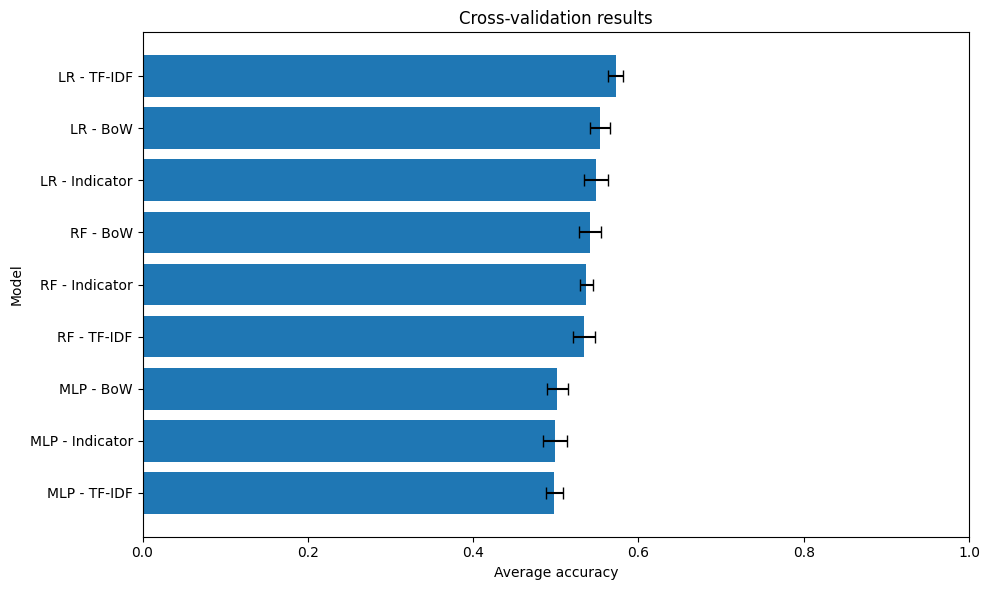

In [25]:
import matplotlib.pyplot as plt

# cross-validation scores together
results = {"LR - BoW": scores_LR_BoW,
    "LR - Indicator": scores_LR_indicator,
    "LR - TF-IDF": scores_LR_tf_idf,
    "MLP - BoW": scores_MLP_BoW,
    "MLP - Indicator": scores_MLP_indicator,
    "MLP - TF-IDF": scores_MLP_tf_idf,
    "RF - BoW": scores_RF_BoW,
    "RF - Indicator": scores_RF_indicator,
    "RF - TF-IDF": scores_RF_tf_idf}

# calculates average accuracy and standard deviation per model
summary = pd.DataFrame({"Model": results.keys(),
    "Mean accuracy": [np.mean(scores) for scores in results.values()],
    "Standard deviation": [np.std(scores) for scores in results.values()]})

# sorts models
summary = summary.sort_values("Mean accuracy", ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10, 6))
plt.barh(summary["Model"], summary["Mean accuracy"], xerr=summary["Standard deviation"], capsize=4)
plt.xlabel("Average accuracy")
plt.ylabel("Model")
plt.title("Cross-validation results")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# *region of practical equivalence (ROPE)*

In [27]:
import baycomp
from itertools import combinations

# cross-validation results
results = {"LR - BoW": scores_LR_BoW,
    "LR - Indicator": scores_LR_indicator,
    "LR - TF-IDF": scores_LR_tf_idf,
    "MLP - BoW": scores_MLP_BoW,
    "MLP - Indicator": scores_MLP_indicator,
    "MLP - TF-IDF": scores_MLP_tf_idf,
    "RF - BoW": scores_RF_BoW,
    "RF - Indicator": scores_RF_indicator,
    "RF - TF-IDF": scores_RF_tf_idf}

rope = 0.005
rope_results = []

# compare every pair of models
for model1, model2 in combinations(results.keys(), 2):
    probs = baycomp.two_on_single(results[model1], results[model2],
        rope=rope)

    p_left, p_rope, p_right = probs

    rope_results.append({"Model 1": model1,
        "Model 2": model2,
        "P(Model 1 better)": p_left,
        "P(Equivalent)": p_rope,
        "P(Model 2 better)": p_right})

rope_summary = pd.DataFrame(rope_results)
print("Bayesian comparison using ROPE = 0.005")
print(rope_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Bayesian comparison using ROPE = 0.005
        Model 1         Model 2  P(Model 1 better)  P(Equivalent)  P(Model 2 better)
       LR - BoW  LR - Indicator             0.4776         0.4836             0.0388
       LR - BoW     LR - TF-IDF             0.0078         0.0310             0.9612
       LR - BoW       MLP - BoW             0.9990         0.0005             0.0005
       LR - BoW MLP - Indicator             0.9985         0.0008             0.0008
       LR - BoW    MLP - TF-IDF             0.9956         0.0021             0.0023
       LR - BoW        RF - BoW             0.7676         0.1741             0.0583
       LR - BoW  RF - Indicator             0.9473         0.0436             0.0090
       LR - BoW     RF - TF-IDF             0.8799         0.0808             0.0393
 LR - Indicator     LR - TF-IDF             0.0053         0.0157             0.9790
 LR - Indicator       MLP - BoW             0.9964         0.0020             0.0017
 LR - Indicator MLP - Indi